# AI-XRay · 04 — Comparación de runs, selección, Model Registry y export

**Proyecto Final Independiente** · César Libardo España Salguero

### Objetivo
1. Comparar todos los runs del experiment `AI-XRay` en MLflow.
2. Elegir el mejor con un **criterio explícito definido antes de mirar el test**.
3. Registrarlo en el **Model Registry**, promoverlo a `Staging` y asignarle el alias `staging`.
4. Exportarlo (`models/aixray_model.keras` + `models/model_card.json`) para la API.
5. Reevaluarlo desde el Registry sobre el **test completo** (302 imágenes nunca usadas para decidir).
6. Fijar el **umbral clínico** y analizar los errores que quedan.
7. Guardar tablas y figuras en `reports/` (son las que van al Executive Summary).

In [1]:
%matplotlib inline
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.keras
from mlflow.tracking import MlflowClient

from src.config import (MLFLOW_MODEL_ALIAS, MLFLOW_MODEL_NAME, MODELS_DIR, REPORTS_DIR,
                        SPLIT_MANIFEST_PATH, TARGET_RECALL, setup_mlflow)
from src.metrics import compute_metrics, save_confusion_matrix, save_roc_curve
from src.preprocessing import dataset_from_manifest
from src.train import predict_dataset

experiment = setup_mlflow()
client = MlflowClient()
REPORTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

# Paleta consistente para todas las figuras del reporte
AZUL, NARANJA, GRIS, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#b9b8b3", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "font.size": 10})

## 1. Comparar los runs del experimento

In [2]:
runs_df = mlflow.search_runs(experiment_ids=[experiment.experiment_id],
                             filter_string="attributes.status = 'FINISHED'")
ETIQUETAS = {
    "ref1_frozen_lr1e-3_do0.3": "Run 1 · congelado LR 1e-3",
    "ref2_frozen_lr1e-4_do0.5": "Run 2 · congelado LR 1e-4 DO 0.5",
    "ref3_finetune_1paso_lr1e-5": "Run 3 · fine-tuning 1 paso",
    "varA_finetune_2fases_lr1e-5": "Var. A · fine-tuning 2 fases",
    "varB_frozen_sin_flip": "Var. B · Run 1 sin flip",
}
runs_df["run"] = runs_df["tags.mlflow.runName"].map(ETIQUETAS).fillna(runs_df["tags.mlflow.runName"])
runs_df["tipo"] = runs_df["tags.tipo"]

cols_val = {"metrics.best_val_loss": "val_loss", "metrics.f1_score": "val_F1", "metrics.recall": "val_recall",
            "metrics.precision": "val_precision", "metrics.auc": "val_AUC"}
cols_test = {"metrics.test_accuracy": "test_acc", "metrics.test_precision": "test_precision",
             "metrics.test_recall": "test_recall", "metrics.test_specificity": "test_especificidad",
             "metrics.test_f1_score": "test_F1", "metrics.test_auc": "test_AUC"}
cols_info = {"metrics.epochs_run": "épocas", "metrics.best_epoch": "mejor_época", "metrics.train_minutes": "min"}

tabla = runs_df.set_index("run")[[*cols_info, *cols_val, *cols_test]].rename(columns={**cols_info, **cols_val, **cols_test})
tabla = tabla.sort_values("val_F1", ascending=False)
tabla.round(4)

,épocas,mejor_época,min,val_loss,val_F1,val_recall,val_precision,val_AUC,test_acc,test_precision,test_recall,test_especificidad,test_F1,test_AUC
run,,,,,,,,,,,,,,
Var. A · fine-tuning 2 fases,10.0,10.0,30.2359,0.1190,0.9620,0.9744,0.9500,0.9914,0.9338,0.9250,0.9487,0.9178,0.9367,0.9867
Run 3 · fine-tuning 1 paso,10.0,10.0,30.1547,0.1213,0.9490,0.9551,0.9430,0.9907,0.9503,0.9548,0.9487,0.9521,0.9518,0.9891
Run 1 · congelado LR 1e-3,10.0,10.0,21.8463,0.1722,0.9367,0.9487,0.9250,0.9823,0.9139,0.9221,0.9103,0.9178,0.9161,0.9792
Var. B · Run 1 sin flip,10.0,10.0,21.4879,0.1764,0.9333,0.9423,0.9245,0.9812,0.9139,0.9167,0.9167,0.9110,0.9167,0.9787
Run 2 · congelado LR 1e-4 DO 0.5,10.0,10.0,23.6038,0.2457,0.9091,0.8974,0.9211,0.9669,0.8874,0.9067,0.8718,0.9041,0.8889,0.9632


**Criterio de selección (fijado antes de mirar el test):**
1. Se ordena por **F1 en validación** (equilibra precisión y sensibilidad).
2. Si dos runs están a menos de 0.01 de F1, desempata el **AUC de validación**: mide la separación entre clases en
   *todos* los umbrales, que es lo que importa cuando después se ajusta el umbral clínico.
3. El test solo se usa para **reportar** el desempeño del modelo elegido, nunca para elegirlo.

In [3]:
cand = tabla.sort_values(["val_F1", "val_AUC"], ascending=False)
top_f1 = cand["val_F1"].iloc[0]
empatados = cand[cand["val_F1"] >= top_f1 - 0.01]
elegido_nombre = empatados.sort_values("val_AUC", ascending=False).index[0]
mejor_run = runs_df[runs_df["run"] == elegido_nombre].iloc[0]

print(f"Runs a <0.01 de F1 del mejor: {list(empatados.index)}")
print(f"Elegido: {elegido_nombre}  (run_id={mejor_run['run_id']})")
print("Justificación registrada en MLflow:", mejor_run.get("tags.justificacion"))
print(tabla.loc[elegido_nombre, ["val_F1", "val_recall", "val_AUC", "val_loss"]].round(4).to_dict())

Runs a <0.01 de F1 del mejor: ['Var. A · fine-tuning 2 fases']
Elegido: Var. A · fine-tuning 2 fases  (run_id=648e23a2957d48a18259a7d879207c38)
Justificación registrada en MLflow: Fine-tuning en dos fases real: parte del modelo del Run 1 (cabeza ya entrenada) en lugar de una cabeza aleatoria como el Run 3.
{'val_F1': 0.962, 'val_recall': 0.9744, 'val_AUC': 0.9914, 'val_loss': 0.119}


### Comparación visual (validación = selección; test = reporte)

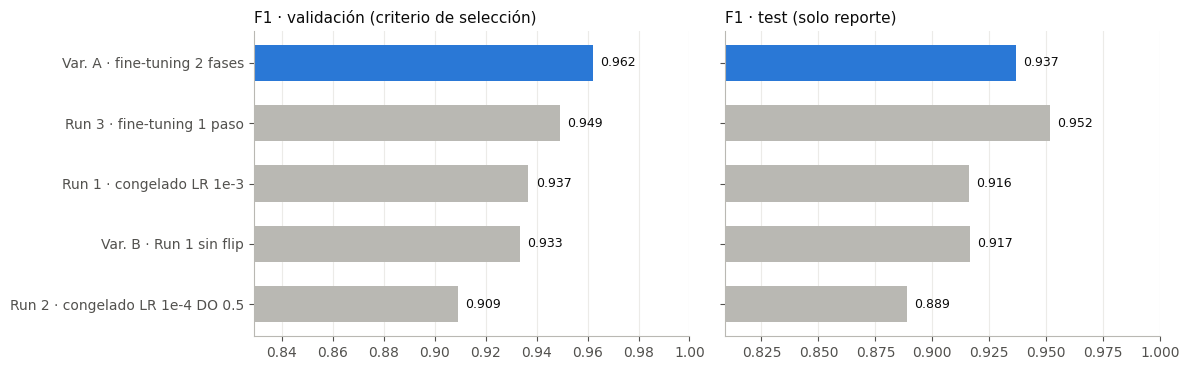

In [4]:
orden = tabla.sort_values("val_F1").index
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, titulo in [(axes[0], "val_F1", "F1 · validación (criterio de selección)"),
                        (axes[1], "test_F1", "F1 · test (solo reporte)")]:
    colores = [AZUL if r == elegido_nombre else GRIS for r in orden]
    vals = tabla.loc[orden, col]
    ax.barh(range(len(orden)), vals, color=colores, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + 0.003, i, f"{v:.3f}", va="center", color=TINTA, fontsize=9)
    ax.set_xlim(max(0, vals.min() - 0.08), 1.0)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=11)
    ax.set_yticks(range(len(orden)), orden)
    ax.grid(axis="x", color="#ecebe8"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "comparacion_runs_f1.png", dpi=200, bbox_inches="tight")
plt.show()

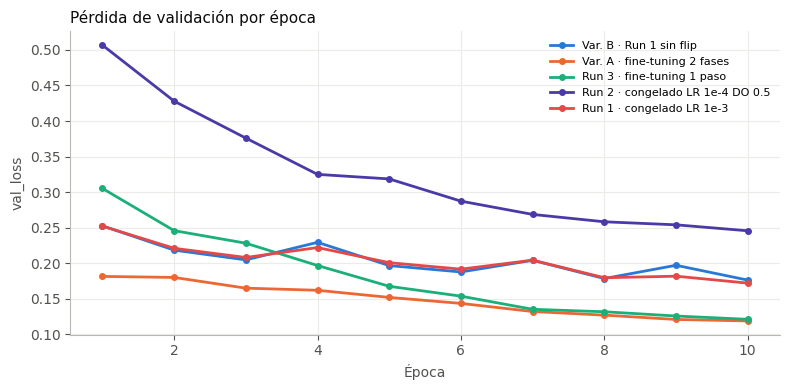

In [5]:
# Curvas de val_loss por época de todos los runs (¿alguno quedó subentrenado?)
fig, ax = plt.subplots(figsize=(8, 4))
paleta = [AZUL, NARANJA, "#1baf7a", "#4a3aa7", "#e34948"]
for (nombre, rid), c in zip(runs_df.set_index("run")["run_id"].items(), paleta):
    hist = client.get_metric_history(rid, "epoch_val_loss")
    xs = [h.step + 1 for h in hist]; ys = [h.value for h in hist]
    ax.plot(xs, ys, color=c, lw=2, label=nombre, marker="o", ms=4)
ax.set_xlabel("Época"); ax.set_ylabel("val_loss")
ax.set_title("Pérdida de validación por época", loc="left", color=TINTA, fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.grid(color="#ecebe8"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "curvas_val_loss.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Registrar el mejor modelo en el Model Registry

Se registra la versión, se promueve al **stage `Staging`** (lo que pide la rúbrica y lo visto en la Clase 3) y además
se le asigna el **alias `staging`**, que es el mecanismo vigente en MLflow 3 (los *stages* están deprecados desde
MLflow 2.9 y Unity Catalog en Databricks solo soporta aliases). La API carga por alias.

In [6]:
import warnings
model_uri = mejor_run.get("tags.logged_model_uri") or f"runs:/{mejor_run['run_id']}/model"
mv = mlflow.register_model(model_uri=model_uri, name=MLFLOW_MODEL_NAME)

client.update_registered_model(
    MLFLOW_MODEL_NAME,
    description=("Clasificador NORMAL/PNEUMONIA de radiografías de tórax pediátricas (ResNet50 + transfer learning). "
                 "Proyecto académico: NO es una herramienta de diagnóstico médico."))
client.update_model_version(
    MLFLOW_MODEL_NAME, mv.version,
    description=f"{elegido_nombre}. Elegido por F1 de validación (desempate por AUC). run_id={mejor_run['run_id']}")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    client.transition_model_version_stage(MLFLOW_MODEL_NAME, mv.version, stage="Staging",
                                          archive_existing_versions=True)
client.set_registered_model_alias(MLFLOW_MODEL_NAME, MLFLOW_MODEL_ALIAS, mv.version)

thr_clin = float(mejor_run["metrics.threshold_clinical"])
for k, v in {"run_name": mejor_run["tags.mlflow.runName"], "selection_criterion": "max val_F1, desempate val_AUC",
             "threshold_clinical": f"{thr_clin:.6f}", "target_recall": str(TARGET_RECALL)}.items():
    client.set_model_version_tag(MLFLOW_MODEL_NAME, mv.version, k, v)

v = client.get_model_version(MLFLOW_MODEL_NAME, mv.version)
print(f"Registrado: {v.name} v{v.version} | stage={v.current_stage} | aliases={v.aliases}")

Registrado: aixray_pneumonia_classifier v1 | stage=Staging | aliases=['staging']


Successfully registered model 'aixray_pneumonia_classifier'.
Created version '1' of model 'aixray_pneumonia_classifier'.


## 3. Exportar el modelo para la API

In [7]:
import tensorflow as tf
best_model = mlflow.keras.load_model(f"models:/{MLFLOW_MODEL_NAME}@{MLFLOW_MODEL_ALIAS}")
# Para servir no hace falta el estado del optimizador (Adam guarda 2 tensores extra por
# cada peso entrenable: ~15 M en fine-tuning). Se exporta arquitectura + pesos: ~95 MB en vez de ~205 MB.
export_model = tf.keras.Model.from_config(best_model.get_config())  # sin compile -> sin optimizador
export_model.set_weights(best_model.get_weights())
export_path = MODELS_DIR / "aixray_model.keras"
export_model.save(export_path)
_x = np.random.default_rng(0).normal(size=(2, 224, 224, 3)).astype("float32")
assert np.allclose(export_model.predict_on_batch(_x), best_model.predict_on_batch(_x), atol=1e-5), "export distinto al registrado"
print("Modelo exportado a:", export_path.relative_to(PROJECT_ROOT), f"({export_path.stat().st_size/1e6:.0f} MB)")

Modelo exportado a: models/aixray_model.keras (95 MB)


## 4. Evaluación final en TEST, cargando el modelo **desde el Registry**

Se recorre el test completo con el modelo recién cargado del Registry (no con el objeto en memoria del entrenamiento):
así se comprueba que lo registrado es exactamente lo que se evaluó.

In [8]:
split = pd.read_csv(SPLIT_MANIFEST_PATH)
val_ds = dataset_from_manifest(split, "val")
test_ds = dataset_from_manifest(split, "test")
y_val, p_val = predict_dataset(best_model, val_ds)
y_test, p_test = predict_dataset(best_model, test_ds)

m05 = compute_metrics(y_test, p_test, 0.5)
mclin = compute_metrics(y_test, p_test, thr_clin)
vclin = compute_metrics(y_val, p_val, thr_clin)
print(f"Test: {len(y_test)} imágenes ({int(y_test.sum())} PNEUMONIA, {int((1 - y_test).sum())} NORMAL)")
print(f"Coincide con lo registrado en el run: F1 test {m05['f1_score']:.4f} vs {mejor_run['metrics.test_f1_score']:.4f}")
print(f"Umbral clínico (fijado en validación para recall >= {TARGET_RECALL:.0%}): {thr_clin:.4f}  "
      f"-> recall en validación {vclin['recall']:.3f}")

final = pd.DataFrame({"Umbral 0.50": m05, f"Umbral clínico {thr_clin:.3f}": mclin}).T
final[["accuracy", "precision", "recall", "specificity", "f1_score", "auc", "tp", "fn", "tn", "fp"]].round(4)

Test: 302 imágenes (156 PNEUMONIA, 146 NORMAL)
Coincide con lo registrado en el run: F1 test 0.9367 vs 0.9367
Umbral clínico (fijado en validación para recall >= 95%): 0.5853  -> recall en validación 0.968


,accuracy,precision,recall,specificity,f1_score,auc,tp,fn,tn,fp
Umbral 0.50,0.9338,0.9250,0.9487,0.9178,0.9367,0.9867,148.0,8.0,134.0,12.0
Umbral clínico 0.585,0.9371,0.9363,0.9423,0.9315,0.9393,0.9867,147.0,9.0,136.0,10.0


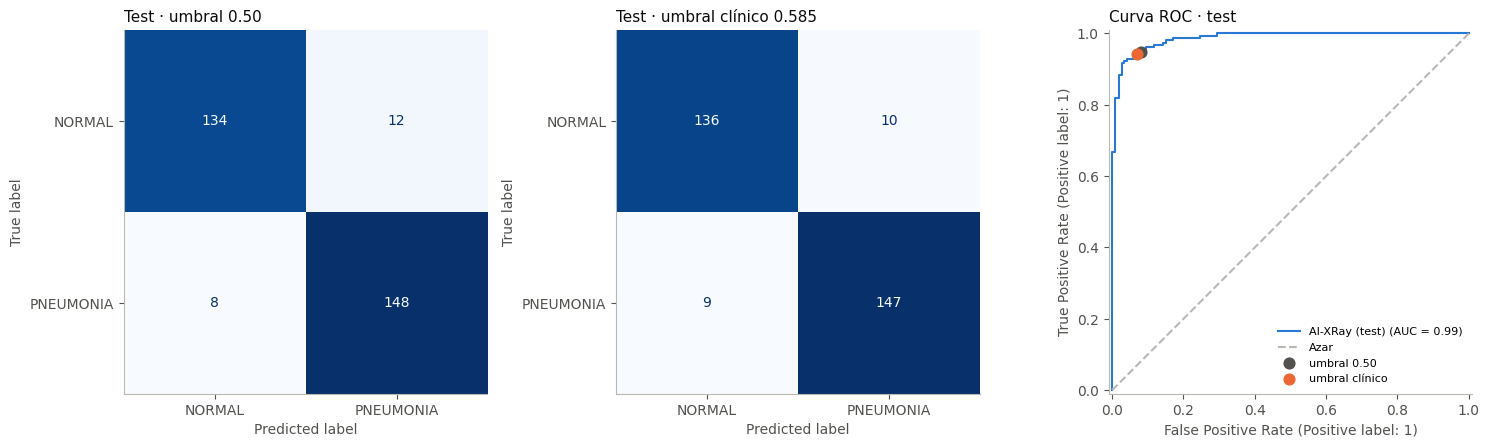

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix
for ax, thr, titulo in [(axes[0], 0.5, "Test · umbral 0.50"), (axes[1], thr_clin, f"Test · umbral clínico {thr_clin:.3f}")]:
    cm = confusion_matrix(y_test, (p_test >= thr).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "PNEUMONIA"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=11)
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[2], name="AI-XRay (test)", color=AZUL)
axes[2].plot([0, 1], [0, 1], ls="--", color=GRIS, label="Azar")
for thr, c, nm in [(0.5, TINTA2, "0.50"), (thr_clin, NARANJA, "clínico")]:
    pred = p_test >= thr
    fpr = (pred & (y_test == 0)).sum() / (y_test == 0).sum(); tpr = (pred & (y_test == 1)).sum() / (y_test == 1).sum()
    axes[2].scatter([fpr], [tpr], color=c, s=60, zorder=5, label=f"umbral {nm}")
axes[2].legend(frameon=False, fontsize=8, loc="lower right")
axes[2].set_title("Curva ROC · test", loc="left", color=TINTA, fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "test_matrices_roc.png", dpi=200, bbox_inches="tight")
plt.show()

## 4b. ¿Las diferencias en test son reales o ruido? (bootstrap pareado)

El test tiene solo 302 imágenes: una diferencia de F1 de 0.01 equivale a 1-2 imágenes. Para no sobreinterpretar,
se remuestrea el test 2,000 veces (con reemplazo, las mismas muestras para todos los runs) usando las predicciones
guardadas como artefacto (`predictions.npz`) de cada run, y se calcula el intervalo de confianza del 95 %.

In [10]:
from sklearn.metrics import f1_score, roc_auc_score
rng = np.random.default_rng(42)
preds = {}
for _, r in runs_df.iterrows():
    local = mlflow.artifacts.download_artifacts(run_id=r["run_id"], artifact_path="predictions.npz")
    d = np.load(local); preds[r["run"]] = (d["y_test"], d["p_test"])

y_ref = next(iter(preds.values()))[0]
assert all(np.array_equal(y_ref, v[0]) for v in preds.values()), "los runs no comparten el mismo test"
idx = rng.integers(0, len(y_ref), size=(2000, len(y_ref)))
boot = {}
for nombre, (y, p) in preds.items():
    yhat = (p >= 0.5).astype(int)
    boot[nombre] = np.array([f1_score(y[i], yhat[i]) for i in idx])

filas = []
for nombre, b in boot.items():
    filas.append({"run": nombre, "test_F1": f1_score(y_ref, (preds[nombre][1] >= 0.5).astype(int)),
                  "IC95_inf": np.percentile(b, 2.5), "IC95_sup": np.percentile(b, 97.5)})
ic = pd.DataFrame(filas).set_index("run").sort_values("test_F1", ascending=False).round(4)
display(ic)

mejor_test = ic.index[0]
if mejor_test != elegido_nombre:
    dif = boot[mejor_test] - boot[elegido_nombre]
    lo, hi = np.percentile(dif, [2.5, 97.5])
    print(f"Diferencia de F1 en test ({mejor_test} − {elegido_nombre}): {dif.mean():+.4f}  IC95 [{lo:+.4f}, {hi:+.4f}]")
    print("-> El intervalo incluye 0: la diferencia NO es estadísticamente distinguible con 302 imágenes."
          if lo <= 0 <= hi else "-> El intervalo excluye 0: la diferencia sí es consistente.")
ic.to_csv(REPORTS_DIR / "test_f1_bootstrap.csv")

,test_F1,IC95_inf,IC95_sup
run,,,
Run 3 · fine-tuning 1 paso,0.9518,0.9268,0.9749
Var. A · fine-tuning 2 fases,0.9367,0.9073,0.9630
Var. B · Run 1 sin flip,0.9167,0.8814,0.9474
Run 1 · congelado LR 1e-3,0.9161,0.8800,0.9471
Run 2 · congelado LR 1e-4 DO 0.5,0.8889,0.8506,0.9241


Diferencia de F1 en test (Run 3 · fine-tuning 1 paso − Var. A · fine-tuning 2 fases): +0.0151  IC95 [-0.0035, +0.0352]
-> El intervalo incluye 0: la diferencia NO es estadísticamente distinguible con 302 imágenes.


## 5. Análisis de errores: falsos negativos que quedan con el umbral clínico

Falsos negativos (neumonías no detectadas): 9 | Falsos positivos (falsas alarmas): 10
Tipo de neumonía en los FN: {'virus': 7, 'bacteria': 2}
Tipo de neumonía en todo el test: {'bacteria': 95, 'virus': 61}


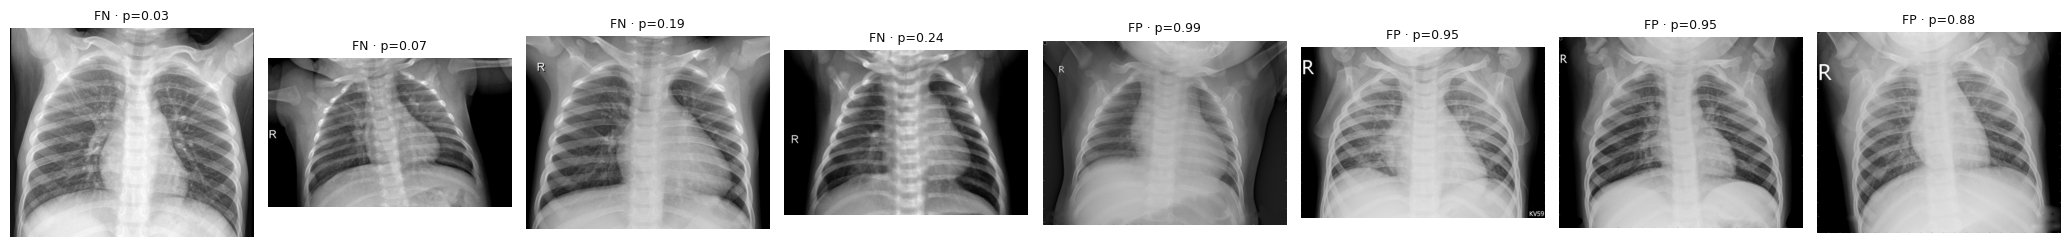

In [11]:
test_rows = split[split["split"] == "test"].reset_index(drop=True)
test_rows["prob"] = p_test
fn = test_rows[(test_rows["label"] == 1) & (test_rows["prob"] < thr_clin)].sort_values("prob")
fp = test_rows[(test_rows["label"] == 0) & (test_rows["prob"] >= thr_clin)].sort_values("prob", ascending=False)
print(f"Falsos negativos (neumonías no detectadas): {len(fn)} | Falsos positivos (falsas alarmas): {len(fp)}")
print("Tipo de neumonía en los FN:", fn["filename"].str.extract(r"_(bacteria|virus)_")[0].value_counts().to_dict())
print("Tipo de neumonía en todo el test:", test_rows[test_rows.label == 1]["filename"].str.extract(r"_(bacteria|virus)_")[0].value_counts().to_dict())

muestras = list(fn.head(4).itertuples()) + list(fp.head(4).itertuples())
if muestras:
    import tensorflow as tf
    fig, axes = plt.subplots(1, len(muestras), figsize=(2.6 * len(muestras), 3))
    axes = np.atleast_1d(axes)
    for ax, r in zip(axes, muestras):
        img = tf.io.decode_image(tf.io.read_file(r.path), channels=1, expand_animations=False).numpy()[..., 0]
        ax.imshow(img, cmap="gray"); ax.axis("off")
        ax.set_title(f"{'FN' if r.label == 1 else 'FP'} · p={r.prob:.2f}", fontsize=9, color=TINTA)
    plt.tight_layout(); plt.show()

## 6. Guardar resultados para el Executive Summary

In [12]:
tabla.round(4).to_csv(REPORTS_DIR / "comparacion_runs.csv")
card = {
    "model_name": MLFLOW_MODEL_NAME,
    "registry_version": int(mv.version),
    "stage": "Staging", "alias": MLFLOW_MODEL_ALIAS,
    "run_id": mejor_run["run_id"], "run_name": mejor_run["tags.mlflow.runName"], "run_label": elegido_nombre,
    "selection_criterion": "max val_F1 (desempate val_AUC si diferencia < 0.01)",
    "threshold_default": 0.5, "threshold_clinical": thr_clin, "target_recall": TARGET_RECALL,
    "test_size": int(len(y_test)), "test_pneumonia": int(y_test.sum()), "test_normal": int((1 - y_test).sum()),
    "test_metrics_threshold_05": m05, "test_metrics_threshold_clinical": mclin,
    "val_metrics_threshold_clinical": vclin,
    "false_negatives_clinical": fn["filename"].tolist(),
}
(MODELS_DIR / "model_card.json").write_text(json.dumps(card, indent=2, ensure_ascii=False), encoding="utf-8")
(REPORTS_DIR / "resumen_final.json").write_text(json.dumps(card, indent=2, ensure_ascii=False), encoding="utf-8")
print("Guardado: models/model_card.json, reports/resumen_final.json, reports/comparacion_runs.csv y figuras en reports/")

Guardado: models/model_card.json, reports/resumen_final.json, reports/comparacion_runs.csv y figuras en reports/


## 7. Inferencia de ejemplo (igual que la API)

In [13]:
from src.preprocessing import preprocess_image_bytes
for r in test_rows.sample(6, random_state=7).itertuples():
    p = float(best_model.predict_on_batch(preprocess_image_bytes(open(r.path, "rb").read())).ravel()[0])
    pred = "PNEUMONIA" if p >= thr_clin else "NORMAL"
    real = "PNEUMONIA" if r.label == 1 else "NORMAL"
    print(f"{'✅' if pred == real else '❌'} real={real:10s} predicho={pred:10s} p={p:.3f}")

✅ real=PNEUMONIA  predicho=PNEUMONIA  p=0.971
✅ real=NORMAL     predicho=NORMAL     p=0.006


✅ real=PNEUMONIA  predicho=PNEUMONIA  p=0.939
✅ real=PNEUMONIA  predicho=PNEUMONIA  p=0.999


✅ real=PNEUMONIA  predicho=PNEUMONIA  p=0.991
✅ real=PNEUMONIA  predicho=PNEUMONIA  p=1.000


## 8. Checklist de autoevaluación

- [x] PySpark para el procesamiento del manifiesto (`01_exploracion.ipynb`, con expresiones nativas, sin UDF).
- [x] Verificación de fuga de datos ejecutada (PNEUMONIA y NORMAL) con `assert`.
- [x] 3 runs de referencia + **2 variantes propias justificadas** (tag `justificacion` en MLflow), mismo presupuesto de épocas.
- [x] Parámetros, métricas por época, métricas finales en val **y test**, artefactos y modelo con *signature* en cada run.
- [x] Mejor modelo registrado, stage `Staging` + alias `staging`.
- [x] Umbral clínico fijado en validación y reportado en test.
- [x] API: `/health` y `/predict` + manejo de errores (400/413/415/503/500) + `pytest`.
- [x] Executive Summary con limitaciones y aviso médico.